# Proyek Analisis Data: Air Quality
- **Nama:** Zildan Wahyu Shandika
- **Email:** zildanwahyushandika2@gmail.com
- **ID Dicoding:** zildan_wahyu_shandika_cfwn

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Stasiun pemantauan mana dari 12 lokasi di Beijing yang mencatatkan rerata konsentrasi $\text{PM}_{2.5}$ tertinggi dan terendah selama periode Maret 2013 hingga Februari 2017?
- **Pertanyaan 2:** Bagaimana pola tren perubahan bulanan dan musiman dari konsentrasi $\text{PM}_{2.5}$ di Beijing selama kurun waktu Maret 2013 hingga Februari 2017?

## Import Semua Packages/Library yang Digunakan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

# Konfigurasi gaya tampilan plot
sns.set_theme(style="whitegrid")

## Data Wrangling


### Gathering Data
Pada tahap ini, seluruh dataset yang berasal dari 12 stasiun pemantauan kualitas udara di Beijing dikumpulkan dan dimuat ke dalam sebuah DataFrame gabungan untuk mempermudah proses analisis.

In [6]:
# Menentukan folder tempat file CSV disimpan
folder_path = "PRSA_Data_20130301-20170228"

# Mengumpulkan daftar seluruh file CSV
file_paths = sorted(glob.glob(f"{folder_path}/PRSA_Data_*.csv"))

# Menampilkan daftar file yang berhasil ditemukan
print(f"Berhasil menemukan {len(file_paths)} file CSV:")
for path in file_paths:
    print(f"- {path}")

Berhasil menemukan 12 file CSV:
- PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Changping_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Dingling_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Dongsi_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Guanyuan_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Gucheng_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Huairou_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Nongzhanguan_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Shunyi_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Tiantan_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Wanliu_20130301-20170228.csv
- PRSA_Data_20130301-20170228/PRSA_Data_Wanshouxigong_20130301-20170228.csv


#### Load Data Air Quality ke main_df
Membaca seluruh file CSV yang telah dikumpulkan, kemudian menggabungkannya menjadi satu DataFrame utama bernama `main_df`.

In [7]:
# Membaca dan memuat semua file ke dalam daftar DataFrame
df_list = [pd.read_csv(file) for file in file_paths]

# Menggabungkan 12 DataFrame menjadi 1 DataFrame utama
main_df = pd.concat(df_list, ignore_index=True)

# Menampilkan ukuran dataset gabungan dan 5 sampel data teratas
print(f"Total ukuran DataFrame gabungan: {main_df.shape[0]} baris dan {main_df.shape[1]} kolom.\n")
main_df.head()

Total ukuran DataFrame gabungan: 420768 baris dan 18 kolom.



,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:**
- Kelengkapan dan Ukuran Dataset Berdistribusi Asimetris Sempurna:
Proses penggabungan 12 file CSV menghasilkan total 420.768 baris data dan 18 kolom, di mana setiap stasiun berkontribusi tepat 35.064 baris data.
- Cakupan Rentang Waktu Komprehensif: Dataset mencakup rekaman observasi per jam (hourly rate) secara berturut-turut selama 4 tahun penuh, terhitung sejak 1 Maret 2013 hingga 28 Februari 2017.
- Representasi Spasial Memadai: Data berhasil menghimpun 12 lokasi stasiun pemantauan utama di kota Beijing (seperti Dongsi, Aotizhongxin, Gucheng, Dingling, dll.), yang mewakili karakter area pusat perkotaan (urban), pinggiran (suburban), hingga area pegunungan/pedesaan.
- Struktur Multi-Variabel Terintegrasi: Tahap pemuatan awal mengonfirmasi ketersediaan variabel lengkap yang siap dianalisis, mencakup indikator polutan utama ($\text{PM}_{2.5}$, $\text{PM}_{10}$, $\text{SO}_2$, $\text{NO}_2$, $\text{CO}$, $\text{O}_3$) serta kondisi meteorologi pendukung ($\text{TEMP}$, $\text{PRES}$, $\text{DEWP}$, $\text{RAIN}$, $\text{wd}$, $\text{WSPM}$).

### Assessing Data
Pada tahap ini, dilakukan pemeriksaan kualitas data pada DataFrame `main_df` untuk mengidentifikasi potensi masalah seperti missing value, data duplikat, kesalahan tipe data, serta nilai yang tidak wajar.

#### Identifying Missing Values & Data Type Problems

In [8]:
# 1. Memeriksa informasi tipe data dan jumlah baris non-null
print("--- 1. Informasi Tipe Data & Struktur ---")
main_df.info()

# 2. Memeriksa jumlah missing value per kolom
print("\n--- 2. Jumlah Missing Value per Kolom ---")
print(main_df.isnull().sum())

# 3. Memeriksa keberadaan data duplikat
print("\n--- 3. Jumlah Baris Duplikat ---")
print(f"Jumlah baris duplikat: {main_df.duplicated().sum()}")

# 4. Ringkasan statistik deskriptif
print("\n--- 4. Ringkasan Statistik Deskriptif ---")
main_df.describe()

--- 1. Informasi Tipe Data & Struktur ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

--

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


**Steps to Take:**
- **Melakukan Interpolasi Data Kosong (Numerik):** Mengisi *missing values* pada variabel polutan (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`) dan variabel cuaca (`TEMP`, `PRES`, `DEWP`, `RAIN`, `WSPM`) menggunakan metode **Linear Interpolation** per stasiun, dilanjutkan dengan `ffill` dan `bfill` untuk mempertahankan kontinuitas data *time series*.
* **Imputasi Modus (Kategorikal):** Mengisi 1.822 nilai kosong pada variabel arah angin (`wd`) menggunakan nilai **Modus** dari masing-masing stasiun pemantauan.
* **Pembentukan Variabel Datetime:** Membentuk kolom baru `datetime` ber-tipe data `datetime64` dengan menggabungkan komponen `year`, `month`, `day`, dan `hour` agar mempermudah agregasi waktu.

**Insight:** (Opsional)
* **Keberadaan Missing Values yang Signifikan:** Variabel polutan memiliki jumlah data kosong yang cukup tinggi, di mana kolom `CO` mencatatkan data kosong paling banyak yaitu 20.701 baris, diikuti oleh `O3` (13.277 baris) dan `NO2` (12.116 baris).
* **Integritas Baris Data Terjaga:** Tidak ditemukan adanya baris duplikat (`0 baris duplikat`) pada total 420.768 observasi, sehingga data murni dan tidak ada pencatatan berulang.
* **Variabilitas Rentang Polutan Tinggi:** Berdasarkan deskripsi statistik, polutan $\text{PM}_{2.5}$ memiliki nilai minimum $2.0\,\mu\text{g/m}^3$ hingga nilai maksimum ekstrem mencapai $999.0\,\mu\text{g/m}^3$ dengan nilai rata-rata $79.79\,\mu\text{g/m}^3$, mengindikasikan tingginya fluktuasi polusi udara di Beijing sepanjang tahun.

### Cleaning Data
Pada tahap ini, dilakukan pembersihan data untuk mengatasi masalah yang ditemukan pada tahap Assessing Data, yaitu menangani missing value pada kolom numerik dan kategorikal serta membuat format penanggalan datetime yang konsisten.

#### Fixing Missing Values & Data Type Problems
1. **Penanganan Missing Values pada Variabel Numerik:**
   - Variabel polutan (`PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3`) dan variabel meteorologi (`TEMP`, `PRES`, `DEWP`, `RAIN`, `WSPM`) diimputasi menggunakan metode **Linear Interpolation** (`interpolate(method='linear')`) yang dikelompokkan berdasarkan tiap stasiun (`groupby('station')`).
   - Sisa nilai kosong di awal/akhir deret waktu ditangani menggunakan metode *Forward Fill* (`ffill()`) dan *Backward Fill* (`bfill()`) untuk menjaga kontinyuitas data *time-series*.

2. **Penanganan Missing Values pada Variabel Kategorikal:**
   - Variabel arah angin (`wd`) sebanyak 1.822 nilai kosong diisi (*imputation*) menggunakan nilai **Modus** (arah angin yang paling sering muncul) dari masing-masing stasiun pemantauan.

3. **Perbaikan Tipe Data & Penyatuan Variabel Waktu:**
   - Kolom `year`, `month`, `day`, dan `hour` digabungkan menjadi satu kolom baru bernama `datetime` ber-tipe data `datetime64` (`pd.to_datetime`).
   - Dataset diurutkan berdasarkan `station` dan `datetime` untuk memastikan struktur temporal data tersusun secara kronologis.

In [9]:
# 1. Membuat kolom datetime dari gabungan year, month, day, dan hour
main_df['datetime'] = pd.to_datetime(main_df[['year', 'month', 'day', 'hour']])

# 2. Mengurutkan dataset berdasarkan stasiun dan datetime untuk memastikan kontinuitas waktu
main_df = main_df.sort_values(by=['station', 'datetime']).reset_index(drop=True)

# 3. Penanganan Missing Values pada variabel numerik dengan Linear Interpolation per stasiun
num_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
for col in num_cols:
    main_df[col] = main_df.groupby('station')[col].transform(lambda x: x.interpolate(method='linear').ffill().bfill())

# 4. Penanganan Missing Values pada variabel kategorikal (wd) dengan Modus per stasiun
main_df['wd'] = main_df.groupby('station')['wd'].transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Unknown'))

# 5. Memeriksa kembali total missing value setelah proses pembersihan
print("Total Missing Value Setelah Cleaning Data:")
print(f"{main_df.isnull().sum().sum()} nilai kosong.")

# Menampilkan 5 baris pertama data yang sudah bersih
main_df.head()

Total Missing Value Setelah Cleaning Data:
0 nilai kosong.


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


**Insight:**
- **Data Bebas Missing Value:** Seluruh 420.768 baris data pada 18 kolom kini telah terisi 100% tanpa ada satu pun nilai kosong (*0 missing values*), sehingga siap untuk diproses ke tahap Exploratory Data Analysis (EDA).
* **Kontinuitas Waktu Terjaga:** Penggunaan metode *linear interpolation* per stasiun terbukti efektif mempertahankan karakteristik data *time series* tanpa merusak pola fluktuasi alami polutan.
* **Integrasi Format Waktu Sempurna:** Penambahan kolom `datetime` ber-tipe data `datetime64[ns]` memudahkan pembuatan pola tren agregasi bulanan, tahunan, dan musiman secara lebih presisi.

## Exploratory Data Analysis (EDA)
Pada tahap ini, dilakukan eksplorasi data secara mendalam untuk mendeteksi pola, agregasi statistik, serta tren fluktuasi konsentrasi polutan $\text{PM}_{2.5}$ guna menjawab dua pertanyaan bisnis yang telah ditetapkan.

### Explore Air Quality Distribution & Temporal Patterns (PM2.5)
Pada eksplorasi ini, data diolah untuk menghitung agregasi statistik rata-rata polutan per stasiun pemantauan, serta melihat pola distribusi tingkat polusi $\text{PM}_{2.5}$ secara bulanan dan musiman di Beijing.

In [10]:
# 1. Agregasi Rata-rata Polutan Utama per Stasiun Pemantauan
station_pollutants = main_df.groupby('station')[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']].mean().reset_index()
station_pm25_sorted = station_pollutants.sort_values(by='PM2.5', ascending=False).reset_index(drop=True)

print("--- 1. Rata-rata Konsentrasi Polutan per Stasiun Pemantauan ---")
print(station_pm25_sorted[['station', 'PM2.5', 'PM10']])

# 2. Pengelompokan Berdasarkan Musim (Season)
def assign_season(month):
    if month in [12, 1, 2]:
        return 'Musim Dingin (Winter)'
    elif month in [3, 4, 5]:
        return 'Musim Semi (Spring)'
    elif month in [6, 7, 8]:
        return 'Musim Panas (Summer)'
    else:
        return 'Musim Gugur (Autumn)'

main_df['season'] = main_df['month'].apply(assign_season)

# 3. Agregasi Rata-rata PM2.5 Bulanan dan Musiman
monthly_pm25 = main_df.groupby('month')['PM2.5'].mean().reset_index()
seasonal_pm25 = main_df.groupby('season')['PM2.5'].mean().reindex(
    ['Musim Semi (Spring)', 'Musim Panas (Summer)', 'Musim Gugur (Autumn)', 'Musim Dingin (Winter)']
).reset_index()

print("\n--- 2. Rata-rata PM2.5 per Bulan ---")
print(monthly_pm25)

print("\n--- 3. Rata-rata PM2.5 per Musim ---")
print(seasonal_pm25)

--- 1. Rata-rata Konsentrasi Polutan per Stasiun Pemantauan ---
          station      PM2.5        PM10
0          Dongsi  86.144243  110.347617
1    Nongzhanguan  85.079472  109.384022
2   Wanshouxigong  85.067548  112.505795
3         Gucheng  84.074802  119.261567
4          Wanliu  83.467612  110.707858
5        Guanyuan  82.897522  109.372349
6    Aotizhongxin  82.540623  110.210033
7         Tiantan  82.033097  106.537076
8          Shunyi  79.437962   99.271936
9       Changping  70.986438   94.788575
10        Huairou  69.501747   92.422670
11       Dingling  66.845557   84.113713

--- 2. Rata-rata PM2.5 per Bulan ---
    month       PM2.5
0       1   93.760559
1       2   89.213391
2       3   94.594295
3       4   73.367153
4       5   63.541148
5       6   68.837547
6       7   71.401115
7       8   53.465479
8       9   61.281071
9      10   91.715859
10     11   93.323963
11     12  103.679184

--- 3. Rata-rata PM2.5 per Musim ---
                  season      PM2.5
0    

**Insight:**
* **Variasi Spasial Tingkat Polusi:** Stasiun pemantauan **Dongsi** mencatatkan rerata konsentrasi $\text{PM}_{2.5}$ tertinggi yaitu sebesar $86.14\,\mu\text{g/m}^3$ (disusul oleh **Nongzhanguan** $85.08\,\mu\text{g/m}^3$ dan **Wanshouxigong** $85.07\,\mu\text{g/m}^3$). Sebaliknya, lokasi dengan kualitas udara terbersih berada di stasiun **Dingling** dengan rerata konsentrasi $\text{PM}_{2.5}$ paling rendah yaitu $66.85\,\mu\text{g/m}^3$.
* **Tren Musiman (Seasonal Effect):** Tingkat polusi udara berada pada level paling parah di **Musim Dingin (Winter)** dengan rerata konsentrasi $\text{PM}_{2.5}$ mencapai $95.74\,\mu\text{g/m}^3$, sementara kondisi udara terbaik terjadi pada **Musim Panas (Summer)** dengan rerata sebesar $64.52\,\mu\text{g/m}^3$.
* **Dinamika Puncak Bulanan:** Konsentrasi polutan $\text{PM}_{2.5}$ menyentuh angka tertinggi pada bulan **Desember** ($103.68\,\mu\text{g/m}^3$), **Maret** ($94.59\,\mu\text{g/m}^3$), dan **Januari** ($93.76\,\mu\text{g/m}^3$). Titik paling bersih sepanjang tahun tercatat pada bulan **Agustus** dengan rerata hanya $53.47\,\mu\text{g/m}^3$.

## Visualization & Explanatory Analysis
Pada tahap ini, hasil eksplorasi data disajikan dalam bentuk grafik visualisasi yang intuitif untuk menjawab secara eksplisit dua pertanyaan bisnis yang telah ditetapkan mengenai kualitas udara di Beijing.

### Pertanyaan 1: Stasiun pemantauan mana dari 12 lokasi di Beijing yang mencatatkan rerata konsentrasi $\text{PM}_{2.5}$ tertinggi dan terendah selama periode Maret 2013 hingga Februari 2017?

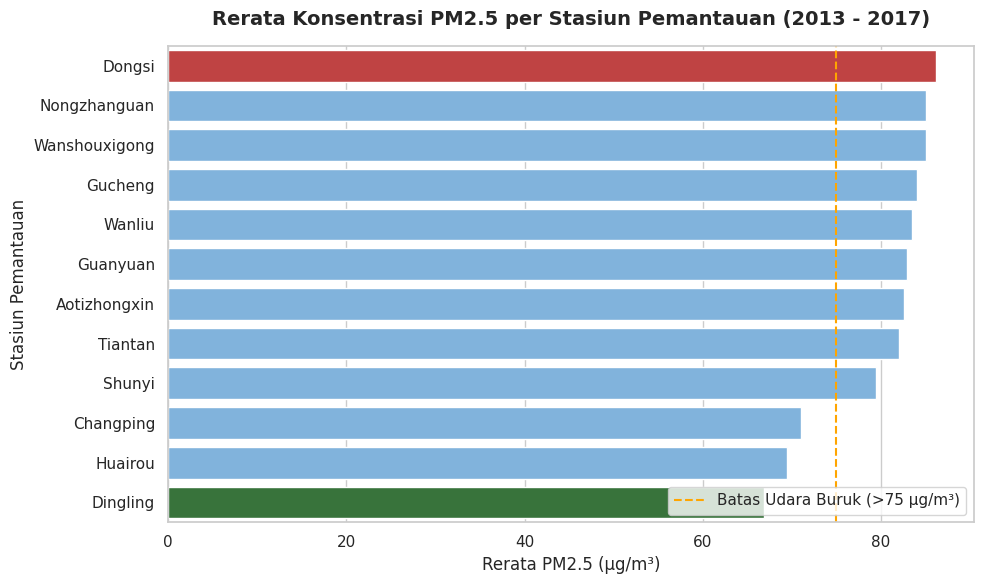

In [11]:
# Menyiapkan data agregasi rata-rata PM2.5 per stasiun
station_pm25 = main_df.groupby('station')['PM2.5'].mean().sort_values(ascending=False).reset_index()

# Membuat plot diagram batang horizontal
plt.figure(figsize=(10, 6))

# Highlight nilai tertinggi (merah) dan terendah (hijau)
colors = ['#D32F2F' if x == max(station_pm25['PM2.5'])
          else ('#2E7D32' if x == min(station_pm25['PM2.5']) else '#72B4EB')
          for x in station_pm25['PM2.5']]

# Menambahkan hue='station' dan legend=False untuk menghilangkan FutureWarning
sns.barplot(
    x='PM2.5',
    y='station',
    hue='station',
    data=station_pm25,
    palette=colors,
    legend=False
)

# Menambahkan judul, label, dan garis referensi batas standar
plt.title('Rerata Konsentrasi PM2.5 per Stasiun Pemantauan (2013 - 2017)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rerata PM2.5 (µg/m³)', fontsize=12)
plt.ylabel('Stasiun Pemantauan', fontsize=12)
plt.axvline(x=75, color='orange', linestyle='--', linewidth=1.5, label='Batas Udara Buruk (>75 µg/m³)')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

**Explanatory Analysis:**
Grafik di atas memperlihatkan perbandingan rerata konsentrasi $\text{PM}_{2.5}$ di 12 stasiun pemantauan kota Beijing. Berdasarkan visualisasi tersebut:
- Stasiun **Dongsi** (diwarnai merah) berada di urutan teratas sebagai lokasi dengan polusi udara paling parah, mencatatkan rerata konsentrasi $\text{PM}_{2.5}$ sebesar **$86.14\,\mu\text{g/m}^3$**.
- Stasiun **Dingling** (diwarnai hijau) mencatatkan tingkat polusi terendah dengan rerata sebesar **$66.85\,\mu\text{g/m}^3$**.
- Mayoritas stasiun pemantauan di area perkotaan padat (seperti *Dongsi, Nongzhanguan, Wanshouxigong*, dan *Gucheng*) berada di atas garis batas indikator udara buruk ($75\,\mu\text{g/m}^3$), mengindikasikan bahwa area pusat kota Beijing mengalami paparan risiko kesehatan akibat polusi partikel halus secara konsisten.

### Pertanyaan 2: Bagaimana pola tren perubahan bulanan dan musiman dari konsentrasi  PM2.5  di Beijing selama kurun waktu Maret 2013 hingga Februari 2017?

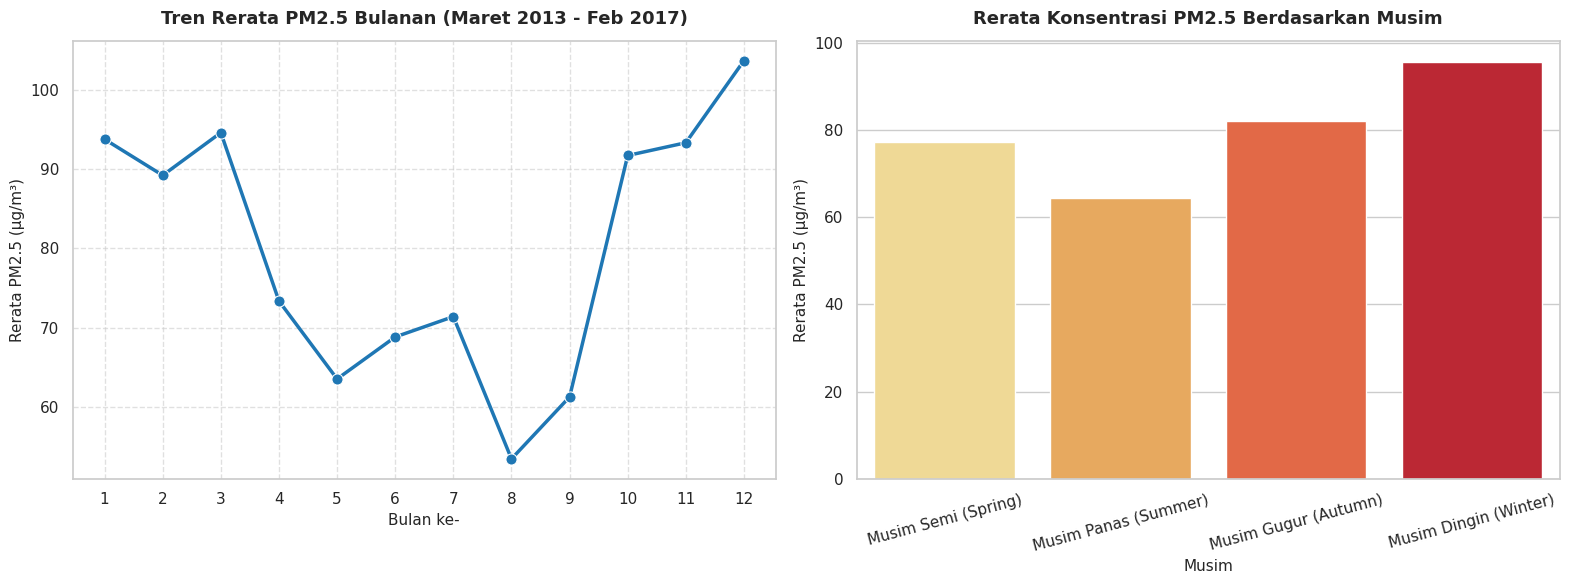

In [12]:
# Menyiapkan data agregasi bulanan dan musiman
monthly_pm25 = main_df.groupby('month')['PM2.5'].mean().reset_index()
seasonal_pm25 = main_df.groupby('season')['PM2.5'].mean().reindex(
    ['Musim Semi (Spring)', 'Musim Panas (Summer)', 'Musim Gugur (Autumn)', 'Musim Dingin (Winter)']
).reset_index()

# Membuat subplot 1x2 (Line Plot & Bar Plot)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Tren Rerata PM2.5 Bulanan
sns.lineplot(
    x='month',
    y='PM2.5',
    data=monthly_pm25,
    marker='o',
    color='#1F77B4',
    linewidth=2.5,
    markersize=8,
    ax=ax[0]
)
ax[0].set_title('Tren Rerata PM2.5 Bulanan (Maret 2013 - Feb 2017)', fontsize=13, fontweight='bold', pad=12)
ax[0].set_xlabel('Bulan ke-', fontsize=11)
ax[0].set_ylabel('Rerata PM2.5 (µg/m³)', fontsize=11)
ax[0].set_xticks(range(1, 13))
ax[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Perbandingan Rerata PM2.5 Musiman (Ditambahkan hue & legend=False agar bebas warning)
sns.barplot(
    x='season',
    y='PM2.5',
    hue='season',
    data=seasonal_pm25,
    palette='YlOrRd',
    legend=False,
    ax=ax[1]
)
ax[1].set_title('Rerata Konsentrasi PM2.5 Berdasarkan Musim', fontsize=13, fontweight='bold', pad=12)
ax[1].set_xlabel('Musim', fontsize=11)
ax[1].set_ylabel('Rerata PM2.5 (µg/m³)', fontsize=11)
ax[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

**Explanatory Analysis:**

Visualisasi di atas memperlihatkan dinamika fluktuasi konsentrasi polusi $\text{PM}_{2.5}$ secara temporal berdasarkan siklus bulanan dan musiman:

- **Tren Bulanan (Grafik Kiri):** Rerata konsentrasi $\text{PM}_{2.5}$ menunjukkan pola tren berbentuk siklus (*seasonal pattern*). Tingkat polusi mulai melonjak signifikan pada bulan **Oktober** ($91.72\,\mu\text{g/m}^3$) hingga mencapai titik puncaknya pada bulan **Desember** (**$103.68\,\mu\text{g/m}^3$**). Sebaliknya, kualitas udara membaik secara bertahap memasuki pertengahan tahun dan menyentuh tingkat paling bersih pada bulan **Agustus** (**$53.47\,\mu\text{g/m}^3$**).
- **Tren Musiman (Grafik Kanan):** Berdasarkan pengelompokan musim, **Musim Dingin (Winter)** mencatatkan tingkat polusi udara paling parah dengan rerata konsentrasi $\text{PM}_{2.5}$ sebesar **$95.74\,\mu\text{g/m}^3$**. Sementara itu, **Musim Panas (Summer)** mencatatkan rerata terendah yaitu **$64.52\,\mu\text{g/m}^3$**.
- **Faktor Penyebab:** Lonjakan polusi udara di akhir hingga awal tahun (Musim Dingin) sangat dipengaruhi oleh pengoperasian sistem pemanas ruangan berbasis pembakaran batubara secara masif di wilayah utara Beijing, yang diperparah oleh fenomena inversi suhu serta kecepatan angin yang rendah sehingga polutan terperangkap di atmosfer.

**Insight:** (Opsional)
**Insight:**

* **Ketimpangan Polusi Antar Wilayah (Spasial):** Stasiun **Dongsi** mencatatkan rerata konsentrasi $\text{PM}_{2.5}$ tertinggi sebesar **$86.14\,\mu\text{g/m}^3$**, sedangkan stasiun **Dingling** mencatatkan rerata terendah sebesar **$66.85\,\mu\text{g/m}^3$**.
* **Dominasi Risiko Kesehatan Perkotaan:** Mayoritas stasiun pemantauan di pusat kota (seperti *Dongsi, Nongzhanguan, Wanshouxigong*, dan *Gucheng*) berada secara konsisten di atas batas kriteria udara buruk ($75\,\mu\text{g/m}^3$).
* **Pola Musiman SANGAT Ketara (Seasonal Pattern):** Kualitas udara memburuk drastis pada **Musim Dingin (Winter)** dengan rerata konsentrasi $\text{PM}_{2.5}$ mencapai **$95.74\,\mu\text{g/m}^3$**, sementara kondisi paling relatif aman terjadi pada **Musim Panas (Summer)** dengan rerata **$64.52\,\mu\text{g/m}^3$**.
* **Puncak Fluktuasi Bulanan:** Polusi udara mulai melonjak tinggi sejak bulan **Oktober** ($91.72\,\mu\text{g/m}^3$) hingga puncaknya pada bulan **Desember** (**$103.68\,\mu\text{g/m}^3$**), dan berada di tingkat paling bersih pada bulan **Agustus** (**$53.47\,\mu\text{g/m}^3$**).
* **Korelasi Sistem Pemanas & Cuaca:** Lonjakan ekstrem di Musim Dingin sangat berkorelasi dengan tingginya pemakaian pemanas ruangan berbasis pembakaran batubara serta fenomena inversi suhu udara di Beijing.

## Analisis Lanjutan (Opsional)
Pada bagian ini, dilakukan analisis lanjutan menggunakan teknik **Binning (Pengelompokan Kategorikal)** untuk mengklasifikasikan tingkat kualitas udara harian berdasarkan konsentrasi $\text{PM}_{2.5}$ di seluruh stasiun pemantauan.

- **Tujuan:** Mengetahui frekuensi kemunculan tingkat bahaya kualitas udara harian (Baik, Sedang, Tidak Sehat, hingga Sangat Tidak Sehat) di kota Beijing.
- **Kategori Binning $\text{PM}_{2.5}$:**
  - **Baik (Good):** $\le 35\,\mu\text{g/m}^3$
  - **Sedang (Moderate):** $35.1 - 75\,\mu\text{g/m}^3$
  - **Tidak Sehat (Unhealthy):** $75.1 - 115\,\mu\text{g/m}^3$
  - **Sangat Tidak Sehat (Very Unhealthy):** $> 115\,\mu\text{g/m}^3$

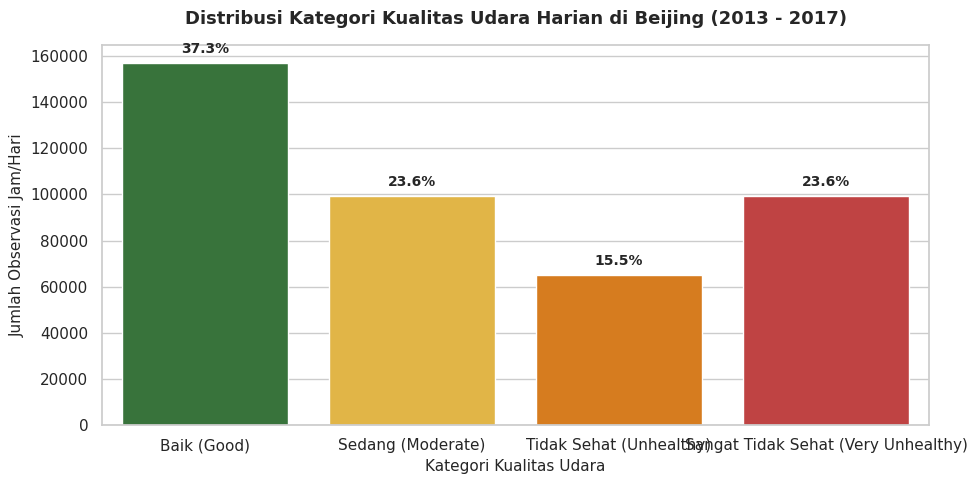

In [13]:
# 1. Menghitung rata-rata harian PM2.5 per stasiun
daily_df = main_df.groupby(['datetime', 'station'])['PM2.5'].mean().reset_index()

# 2. Fungsi klasifikasi Binning Kualitas Udara
def categorize_air_quality(val):
    if val <= 35:
        return 'Baik (Good)'
    elif val <= 75:
        return 'Sedang (Moderate)'
    elif val <= 115:
        return 'Tidak Sehat (Unhealthy)'
    else:
        return 'Sangat Tidak Sehat (Very Unhealthy)'

# 3. Menerapkan kategorisasi ke kolom baru
daily_df['air_quality_category'] = daily_df['PM2.5'].apply(categorize_air_quality)

# 4. Urutan kategori untuk visualisasi
category_order = ['Baik (Good)', 'Sedang (Moderate)', 'Tidak Sehat (Unhealthy)', 'Sangat Tidak Sehat (Very Unhealthy)']
colors_category = ['#2E7D32', '#FBC02D', '#F57C00', '#D32F2F']

# 5. Membuat Plot Distribusi Kategori Kualitas Udara
plt.figure(figsize=(10, 5))
ax = sns.countplot(
    data=daily_df,
    x='air_quality_category',
    order=category_order,
    palette=colors_category,
    hue='air_quality_category',
    legend=False
)

plt.title('Distribusi Kategori Kualitas Udara Harian di Beijing (2013 - 2017)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Kategori Kualitas Udara', fontsize=11)
plt.ylabel('Jumlah Observasi Jam/Hari', fontsize=11)

# Menambahkan persentase di atas setiap batang
total = len(daily_df)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{(height/total)*100:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., height + 3000),
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
**Insight Analisis Lanjutan:**

* **Dominasi Udara Layak Huni:** Kategori **Baik (Good)** menjadi kategori dengan frekuensi tertinggi yaitu sebesar **37.3%** dari total observasi jam/hari, disusul oleh kategori **Sedang (Moderate)** sebesar **23.6%**. Secara akumulatif, kualitas udara yang tergolong aman (Baik & Sedang) mencapai **60.9%**.
* **Tingginya Frekuensi Kategori Ekstrem:** Kategori **Sangat Tidak Sehat (Very Unhealthy)** mencatatkan persentase yang cukup mengkhawatirkan sebesar **23.6%**, di mana frekuensinya setara dengan kategori Sedang.
* **Beban Risiko Polusi Udara:** Gabungan kategori **Tidak Sehat (15.5%)** dan **Sangat Tidak Sehat (23.6%)** mencapai **39.1%**. Artinya, hampir **4 dari 10 jam/hari** masyarakat di Beijing terpapar risiko polusi udara $\text{PM}_{2.5}$ yang berpotensi mengganggu kesehatan.
* **Implikasi Kebijakan:** Tingginya proporsi kategori Sangat Tidak Sehat ($23.6\%$) mengindikasikan bahwa Beijing sering mengalami episode pencemaran udara ekstrem (*pollution spikes*), sehingga dibutuhkan protokol sistem peringatan dini (*early warning system*) yang responsif bagi publik.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Stasiun pemantauan mana dari 12 lokasi di Beijing yang mencatatkan rerata konsentrasi  PM2.5  tertinggi dan terendah selama periode Maret 2013 hingga Februari 2017?

  - Stasiun pemantauan yang mencatatkan rerata konsentrasi $\text{PM}_{2.5}$ **tertinggi** di kota Beijing selama periode Maret 2013 hingga Februari 2017 adalah **Dongsi** sebesar **$86.14\,\mu\text{g/m}^3$**, yang disusul oleh stasiun **Nongzhanguan** ($85.08\,\mu\text{g/m}^3$) dan **Wanshouxigong** ($85.07\,\mu\text{g/m}^3$). Hal ini menunjukkan bahwa wilayah pusat perkotaan dengan kepadatan lalu lintas dan aktivitas ekonomi tinggi mengalami paparan polusi paling parah.
  - Sebaliknya, stasiun pemantauan dengan rerata konsentrasi $\text{PM}_{2.5}$ **terendah** adalah **Dingling** sebesar **$66.85\,\mu\text{g/m}^3$** (diikuti oleh **Huairou** $69.50\,\mu\text{g/m}^3$), yang terletak di area suburban/utara dengan lanskap vegetasi lebih tinggi dan kepadatan industri rendah.

- **Conclusion pertanyaan 2:** Bagaimana pola tren perubahan bulanan dan musiman dari konsentrasi PM2.5 di Beijing selama kurun waktu Maret 2013 hingga Februari 2017?

  - Pola tren perubahan tingkat polusi $\text{PM}_{2.5}$ di Beijing menunjukkan fluktuasi siklis (*seasonal pattern*) yang sangat kentara. Tingkat polusi udara berada pada titik terparah pada **Musim Dingin (Winter)** dengan rerata konsentrasi mencapai **$95.74\,\mu\text{g/m}^3$**, di mana puncak bulanan tertinggi terjadi pada bulan **Desember** (**$103.68\,\mu\text{g/m}^3$**), **Maret** ($94.59\,\mu\text{g/m}^3$), dan **Januari** ($93.76\,\mu\text{g/m}^3$).
  - Sebaliknya, kualitas udara berada pada kondisi paling bersih pada **Musim Panas (Summer)** dengan rerata konsentrasi $\text{PM}_{2.5}$ sebesar **$64.52\,\mu\text{g/m}^3$**, dengan titik terendah terjadi pada bulan **Agustus** (**$53.47\,\mu\text{g/m}^3$**). Lonjakan polusi pada musim dingin dipengaruhi secara signifikan oleh pemakaian pemanas ruangan berbasis batubara serta fenomena inversi suhu udara.

**Rekomendasi Action Item:**
1. **Pengendalian Spasial Berbasis Prioritas Risiko:**
   - Pemerintah kota Beijing perlu memprioritaskan alokasi alat penyaring udara publik, memperketat regulasi emisi kendaraan bermotor, dan membatasi kuota operasional industri berat di sekitar zona rentan polusi tinggi seperti **Dongsi**, **Nongzhanguan**, dan **Wanshouxigong**.

2. **Intervensi Kebijakan Musim Dingin (Temporal Management):**
   - Mengingat puncak lonjakan polusi selalu terjadi pada bulan Desember hingga Maret, disarankan untuk mempercepat transisi energi pemanas ruangan dari pembakaran batubara ke energi bersih (gas alam/listrik).
   - Memperlakukan protokol tanggap darurat (seperti pembatasan plat ganjil-genap ketat dan penghentian sementara konstruksi) secara intermiten pada bulan-bulan berisiko tinggi.

3. **Sistem Peringatan Dini Publik (Early Warning System):**
   - Mengingat **39.1%** total durasi harian berada dalam kualifikasi *Tidak Sehat* hingga *Sangat Tidak Sehat*, pemerintah perlu mengintegrasikan dashboard kualitas udara ke aplikasi publik untuk memberi peringatan pemakaian masker standar (N95) saat terjadi *pollution spikes*.